The same steps as notebook 01, for the CNN: load ResNet-18, fine-tune it into the base model with the same recipe, and run the same prune test. It answers the question: *with the recipe chosen for both models, does ResNet-18 reach a comparable base model, and does it recover after pruning?* (PLAN.md, Steps: "Decide what to do with the CNN": the CNN gets exactly the ViT's recipe, so the architecture is the only difference.)

# Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import Subset

import data
import models
import pruning
import sweep
import train

`QUICK_TEST = True` runs every cell on a few hundred images in a few minutes (Rule 3: tiny first).
Set it to `False` for the real run, a bit over an hour on the M3 Pro. The real run saves everything to
`checkpoints/cnn/`, and cells skip work that is already saved, so running the notebook again
afterwards takes only minutes.

In [2]:
QUICK_TEST = False  # True: a few hundred images, to check that everything runs. False: the real run.

ARCH = "cnn"  # "vit" (DeiT-Tiny) or "cnn" (ResNet-18)
SEED = 0
IMG_SIZE = 224  # CIFAR-10's 32x32 images are upscaled to the size both models were pretrained at
BASE_EPOCHS = 3
FINETUNE_EPOCHS = 1
SPARSITIES = [0.3, 0.5, 0.7, 0.9, 0.95]
METHODS = ["magnitude", "random"]
SKIP = models.SKIP[ARCH]  # the first and last layers are never pruned (PLAN.md: Pruning)

RUN_DIR = Path(f"checkpoints/{ARCH}-quick-test" if QUICK_TEST else f"checkpoints/{ARCH}")
RUN_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(SEED)
print("device:", device)

device: mps


# Data
45,000 training images and 5,000 validation images (500 per class). The validation indices are
drawn once with a fixed seed and saved to `splits/val_indices.npy`, so every run, and every model,
uses the same split. The test set and CIFAR-10H are not loaded here (Rule 7).

In [3]:
train_set, val_set = data.train_val_sets()
labels = np.array(val_set.dataset.targets)
print("validation images per class:", np.bincount(labels[val_set.indices]))
assert not set(train_set.indices) & set(val_set.indices), "train and validation overlap"

if QUICK_TEST:
    train_set = Subset(train_set, range(512))
    val_set = Subset(val_set, range(256))
train_loader = data.loader(train_set, shuffle=True)
val_loader = data.loader(val_set, batch_size=256)
print(f"train: {len(train_set):,} images, validation: {len(val_set):,} images")

validation images per class: [500 500 500 500 500 500 500 500 500 500]
train: 45,000 images, validation: 5,000 images


# Model
ResNet-18 with torchvision's original ImageNet weights (timm's `resnet18.tv_in1k` is the same
checkpoint). `num_classes=10` swaps the 1,000-class `fc` layer for a new, untrained 10-class one.
First, a check on a few images (Rule 3): the output should have one row per image and 10 columns,
and before fine-tuning, accuracy should be near chance (10%).

In [4]:
model = models.new_model(ARCH, pretrained=True, device=device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

images, _ = next(iter(val_loader))
model.eval()
with torch.no_grad():
    logits = model(train.upscale(images[:8].to(device), IMG_SIZE))
print("output shape for 8 images:", tuple(logits.shape))
print(f"validation accuracy before fine-tuning: {train.accuracy(model, val_loader, device, IMG_SIZE):.1%}")

11,181,642 parameters
output shape for 8 images: (8, 10)


validation accuracy before fine-tuning: 9.3%


## Timing (Rule 3)
Twenty training steps on a throwaway copy, to estimate how long the real run takes. If it's too
long, PLAN.md says to drop the image size to 128×128.

In [5]:
sec = train.seconds_per_step(models.new_model(ARCH, pretrained=True, device=device), train_loader, device, IMG_SIZE)
steps_per_epoch = 45_000 // 128 + 1  # for the real run, even in quick-test mode
epochs = BASE_EPOCHS + FINETUNE_EPOCHS * (len(METHODS) * len(SPARSITIES) + 1)
print(f"{sec:.2f} s per step -> {sec * steps_per_epoch / 60:.1f} min per epoch")
print(f"real run: {epochs} epochs, about {sec * steps_per_epoch * epochs / 3600:.1f} hours of training")

0.60 s per step -> 3.5 min per epoch
real run: 14 epochs, about 0.8 hours of training


# Base model
Fine-tune for 3 epochs on the 45,000 training images: AdamW, peak learning rate 1e-4, weight decay
0.05, batch size 128, a short warm-up, then cosine decay. Validation accuracy is checked after every
epoch. PLAN.md's bar: if it ends below ~94%, or is still clearly improving at epoch 3, change one
thing (learning rate or epochs), judged on validation only.

**Prediction (Rule 6, written by the AI assistant on 2026-10-25, before the real run):** ResNet-18 ends at 94–96%, a little below DeiT-Tiny, again with less than 1 point gained from epoch 2 to epoch 3.

In [6]:
base_path = RUN_DIR / "base.pt"
history_path = RUN_DIR / "base_history.json"

if base_path.exists():
    model.load_state_dict(torch.load(base_path, map_location=device))
    history = json.loads(history_path.read_text())
    print("loaded the saved base model")
else:
    torch.manual_seed(SEED)
    history = train.train(model, train_loader, BASE_EPOCHS, device, IMG_SIZE, val_loader)
    torch.save(model.state_dict(), base_path)
    history_path.write_text(json.dumps(history, indent=1))

for row in history:
    print(f"epoch {row['epoch']}: train loss {row['train_loss']:.3f}, "
          f"validation accuracy {row['val_acc']:.2%} ({row['minutes']:.1f} min)")

epoch 1: train loss 0.512, validation accuracy 93.36% (3.6 min)
epoch 2: train loss 0.156, validation accuracy 94.88% (3.6 min)
epoch 3: train loss 0.098, validation accuracy 95.04% (3.7 min)


# Pruning
Global unstructured pruning (PLAN.md: Pruning):
- **magnitude**: the smallest weights (by |w|) across all prunable layers at once are set to zero,
  so some layers lose more than others.
- **random**, the control: the same number of weights, chosen at random.

Only the weights of the convolutions inside the four residual stages are pruned (the 3×3 convs and
the 1×1 `downsample` convs). Biases, BatchNorm layers, the first conv (`conv1`) and the 10-class
`fc` layer (last layer) are left alone. *Sparsity* is the share of these
prunable weights that are zero.

First, a check on a throwaway copy: 50% magnitude pruning should zero exactly half the prunable
weights, and every zeroed weight should be at least as small as every weight that's kept.

In [7]:
layers = pruning.prunable(model, SKIP)
n_prunable = sum(module.weight.numel() for module, _ in layers)
n_total = sum(p.numel() for p in model.parameters())
print(f"{len(layers)} prunable layers: {n_prunable:,} of {n_total:,} parameters ({n_prunable / n_total:.0%})")

check = models.new_model(ARCH, pretrained=False, device=device)
check.load_state_dict(model.state_dict())
before = torch.cat([m.weight.detach().abs().flatten() for m, _ in pruning.prunable(check, SKIP)])
pruning.global_prune(check, SKIP, 0.5, "magnitude")
mask = torch.cat([m.weight_mask.flatten() for m, _ in pruning.prunable(check, SKIP)])
print(f"sparsity after 50% pruning: {pruning.sparsity(check, SKIP):.4f}")
print("largest pruned |w| <= smallest kept |w|:", (before[mask == 0].max() <= before[mask == 1].min()).item())

19 prunable layers: 11,157,504 of 11,181,642 parameters (100%)
sparsity after 50% pruning: 0.5000
largest pruned |w| <= smallest kept |w|: True


## Prune, then fine-tune for 1 epoch
For each method and sparsity (`sweep.run`): start from the base model, prune it, measure validation
accuracy, fine-tune for 1 epoch with the pruned weights held at zero, and measure again. The
unpruned model (`none_0`) also gets the extra epoch, so the extra training isn't mistaken for an
effect of pruning. Both versions of every model are saved for the final test-set evaluation
(notebook 03). Here, validation only checks that each pruned model recovers.

**Prediction (Rule 6, written by the AI assistant on 2026-10-25, before the real run):** the same shape as the ViT, but ResNet-18 holds up better under magnitude pruning at 90–95% (CNNs are known to be very compressible). Right after pruning its accuracy falls faster than the ViT's, partly because BatchNorm's running statistics no longer match the pruned weights until the fine-tune updates them.

In [8]:
results = sweep.run(ARCH, RUN_DIR, train_loader, val_loader, device, IMG_SIZE, METHODS, SPARSITIES,
                    FINETUNE_EPOCHS, SEED)

       none_0: 95.04% after pruning -> 95.22% after fine-tuning (3.7 min)


 magnitude_30: 95.14% after pruning -> 95.36% after fine-tuning (3.8 min)


 magnitude_50: 93.90% after pruning -> 95.20% after fine-tuning (3.7 min)


 magnitude_70: 85.50% after pruning -> 94.82% after fine-tuning (3.6 min)


 magnitude_90: 10.12% after pruning -> 91.54% after fine-tuning (3.6 min)


 magnitude_95: 11.22% after pruning -> 84.30% after fine-tuning (3.9 min)


    random_30: 10.00% after pruning -> 93.26% after fine-tuning (3.8 min)


    random_50: 9.88% after pruning -> 89.18% after fine-tuning (3.8 min)


    random_70: 10.00% after pruning -> 67.72% after fine-tuning (3.8 min)


    random_90: 10.00% after pruning -> 48.30% after fine-tuning (3.8 min)


    random_95: 10.00% after pruning -> 39.94% after fine-tuning (3.7 min)


## Validation accuracy vs sparsity
Dashed lines with open markers: right after pruning. Solid lines: after the 1-epoch fine-tune.
The 0% point is the base model (dashed) and the base model plus the extra epoch (solid).

   method sparsity measured val acc pruned val acc fine-tuned
magnitude      30%   0.3000         95.14%             95.36%
magnitude      50%   0.5000         93.90%             95.20%
magnitude      70%   0.7000         85.50%             94.82%
magnitude      90%   0.9000         10.12%             91.54%
magnitude      95%   0.9500         11.22%             84.30%
     none       0%   0.0000         95.04%             95.22%
   random      30%   0.3000         10.00%             93.26%
   random      50%   0.5000          9.88%             89.18%
   random      70%   0.7000         10.00%             67.72%
   random      90%   0.9000         10.00%             48.30%
   random      95%   0.9500         10.00%             39.94%


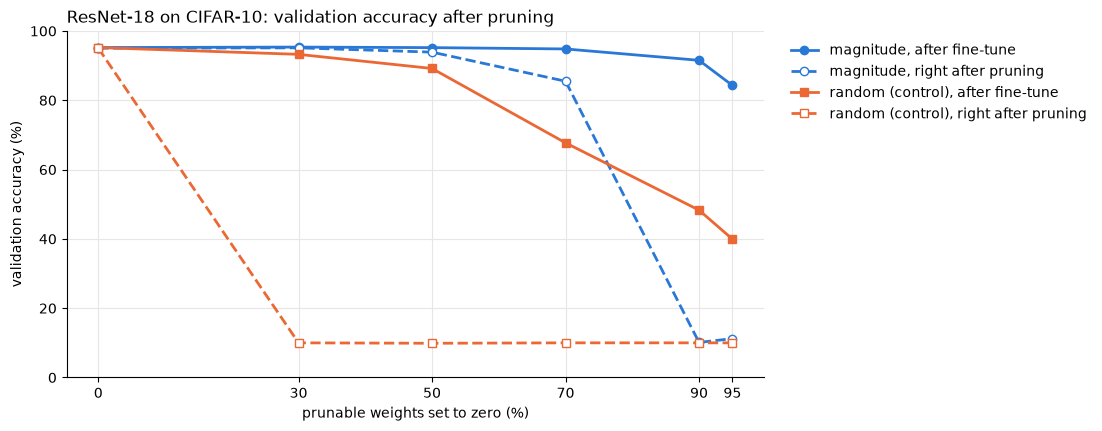

In [9]:
sweep.print_table(results)
sweep.plot_validation(results, METHODS, SPARSITIES, "ResNet-18 on CIFAR-10: validation accuracy after pruning")
plt.show()

# What happened (Rule 4)
*Drafted with an AI assistant on 2026-10-25.*

- **What happened:** the base model reached 95.0% validation accuracy (93.4% → 94.9% → 95.0%), above the 94% bar and no longer improving, so the recipe stayed as it was. The base-model prediction held. After the fine-tune, magnitude pruning keeps 95.4%, 95.2%, 94.8%, 91.5% and 84.3% at 30/50/70/90/95%, and random pruning keeps 93.3%, 89.2%, 67.7%, 48.3% and 39.9%. As predicted, ResNet-18 holds up far better than DeiT-Tiny at 90–95% (91.5% vs 38.4% at 90%). The other half of the prediction was wrong: right after pruning, ResNet-18 falls *more slowly* than DeiT-Tiny (85.5% vs 17.7% at 70%), and only collapses to chance at 90%.
- **What we learned:** ResNet-18 is very compressible. 90% of its prunable weights can go for 3.7 points of validation accuracy after one epoch. Random pruning destroys it right after pruning even at 30%, but one epoch brings most of that back at low sparsity.
- **Open questions:** how much of the collapse right after pruning is stale BatchNorm statistics? Re-estimating them on a few training batches, with no fine-tune, would tell.